In [1]:
!pip -q install kagglehub pymupdf scikit-image torchmetrics torch-fidelity

In [2]:
import os
import glob
import json
import math
import random
import time
import io
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFilter, ImageEnhance, ImageDraw
import fitz  # PyMuPDF

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity as ssim

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Training on CPU will be much slower.")

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [3]:

import os
import glob
import kagglehub

# Download the dataset
DATASET_PATH = kagglehub.dataset_download(
    "snehaanbhawal/resume-dataset"
)

print("Dataset downloaded to:", DATASET_PATH)

# Find all PDF files, including those in subfolders
pdf_files = glob.glob(
    os.path.join(DATASET_PATH, "**", "*.pdf"),
    recursive=True
)

print("Number of PDF files found:", len(pdf_files))

# Display the first 10 PDF paths
for p in pdf_files[:10]:
    print(p)

# Stop if no PDFs were found
assert len(pdf_files) > 0, (
    "No PDFs found. Inspect the downloaded dataset structure "
    "before proceeding."
)


Using Colab cache for faster access to the 'resume-dataset' dataset.
Dataset downloaded to: /kaggle/input/resume-dataset
Number of PDF files found: 2484
/kaggle/input/resume-dataset/data/data/DESIGNER/22506245.pdf
/kaggle/input/resume-dataset/data/data/DESIGNER/13998435.pdf
/kaggle/input/resume-dataset/data/data/DESIGNER/67582956.pdf
/kaggle/input/resume-dataset/data/data/DESIGNER/34349255.pdf
/kaggle/input/resume-dataset/data/data/DESIGNER/26790545.pdf
/kaggle/input/resume-dataset/data/data/DESIGNER/12674307.pdf
/kaggle/input/resume-dataset/data/data/DESIGNER/11807040.pdf
/kaggle/input/resume-dataset/data/data/DESIGNER/44145704.pdf
/kaggle/input/resume-dataset/data/data/DESIGNER/27497542.pdf
/kaggle/input/resume-dataset/data/data/DESIGNER/11155153.pdf


In [4]:

import os
import random
import math
import json
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFilter, ImageEnhance
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = torch.device("cpu")
    print("Using CPU — training may be slow.")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device configured:", DEVICE)


PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
Device configured: cuda


In [5]:

import fitz  # PyMuPDF
from PIL import Image, ImageOps
from tqdm.auto import tqdm

# Output folder for processed resume images
PROCESSED_DIR = "/content/resume_images"
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Image dimensions: height, width
IMAGE_SIZE = (512, 384)

processed_images = []
failed_pdfs = []

for idx, pdf_path in enumerate(tqdm(pdf_files, desc="Processing resumes")):
    try:
        document = fitz.open(pdf_path)

        if len(document) == 0:
            failed_pdfs.append(pdf_path)
            document.close()
            continue

        # Render the first page at 150 DPI
        page = document[0]
        pix = page.get_pixmap(
            matrix=fitz.Matrix(150 / 72, 150 / 72),
            colorspace=fitz.csGRAY,
            alpha=False
        )

        image = Image.frombytes(
            "L",
            [pix.width, pix.height],
            pix.samples
        )

        # Fit the page into a consistent size without stretching
        image.thumbnail((IMAGE_SIZE[1], IMAGE_SIZE[0]))

        canvas = Image.new("L", (IMAGE_SIZE[1], IMAGE_SIZE[0]), 255)
        x = (canvas.width - image.width) // 2
        y = (canvas.height - image.height) // 2
        canvas.paste(image, (x, y))

        output_path = os.path.join(
            PROCESSED_DIR, f"resume_{idx:05d}.png"
        )
        canvas.save(output_path)

        processed_images.append(output_path)
        document.close()

    except Exception as e:
        failed_pdfs.append(pdf_path)
        print(f"Could not process {pdf_path}: {e}")

print("\nPDF files found:", len(pdf_files))
print("Images successfully processed:", len(processed_images))
print("PDFs that failed:", len(failed_pdfs))
print("Processed image folder:", PROCESSED_DIR)

assert len(processed_images) > 0, (
    "No images were processed. Check the PDF files and errors above."
)


Processing resumes:   0%|          | 0/2484 [00:00<?, ?it/s]


PDF files found: 2484
Images successfully processed: 2484
PDFs that failed: 0
Processed image folder: /content/resume_images


In [6]:

import fitz  # PyMuPDF
from PIL import Image, ImageOps
from tqdm.auto import tqdm

# Output folder for processed resume images
PROCESSED_DIR = "/content/resume_images"
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Image dimensions: height, width
IMAGE_SIZE = (512, 384)

processed_images = []
failed_pdfs = []

for idx, pdf_path in enumerate(tqdm(pdf_files, desc="Processing resumes")):
    try:
        document = fitz.open(pdf_path)

        if len(document) == 0:
            failed_pdfs.append(pdf_path)
            document.close()
            continue

        # Render the first page at 150 DPI
        page = document[0]
        pix = page.get_pixmap(
            matrix=fitz.Matrix(150 / 72, 150 / 72),
            colorspace=fitz.csGRAY,
            alpha=False
        )

        image = Image.frombytes(
            "L",
            [pix.width, pix.height],
            pix.samples
        )

        # Fit the page into a consistent size without stretching
        image.thumbnail((IMAGE_SIZE[1], IMAGE_SIZE[0]))

        canvas = Image.new("L", (IMAGE_SIZE[1], IMAGE_SIZE[0]), 255)
        x = (canvas.width - image.width) // 2
        y = (canvas.height - image.height) // 2
        canvas.paste(image, (x, y))

        output_path = os.path.join(
            PROCESSED_DIR, f"resume_{idx:05d}.png"
        )
        canvas.save(output_path)

        processed_images.append(output_path)
        document.close()

    except Exception as e:
        failed_pdfs.append(pdf_path)
        print(f"Could not process {pdf_path}: {e}")

print("\nPDF files found:", len(pdf_files))
print("Images successfully processed:", len(processed_images))
print("PDFs that failed:", len(failed_pdfs))
print("Processed image folder:", PROCESSED_DIR)

assert len(processed_images) > 0, (
    "No images were processed. Check the PDF files and errors above."
)


Processing resumes:   0%|          | 0/2484 [00:00<?, ?it/s]


PDF files found: 2484
Images successfully processed: 2484
PDFs that failed: 0
Processed image folder: /content/resume_images


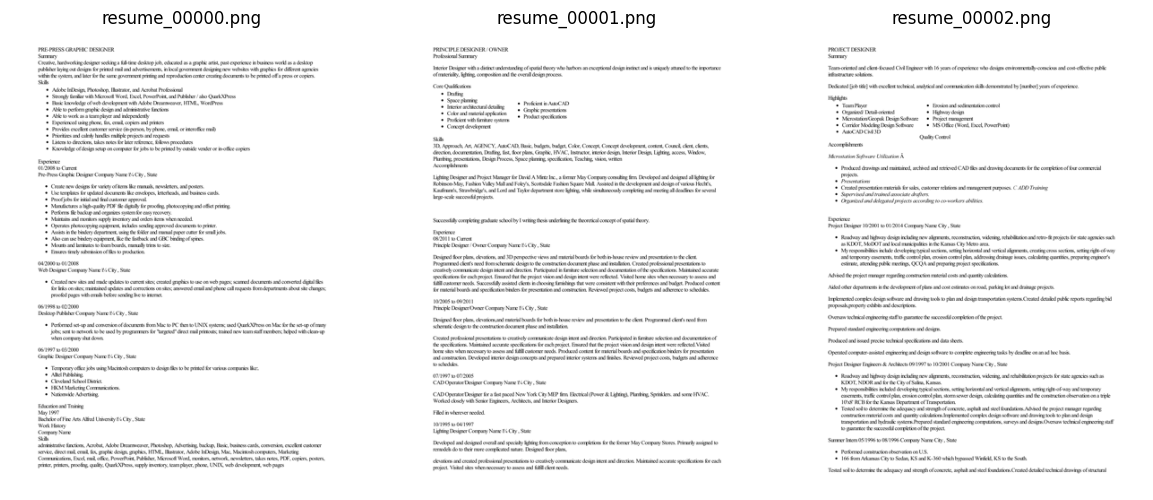

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, image_path in zip(axes, processed_images[:3]):
    image = Image.open(image_path).convert("L")
    ax.imshow(image, cmap="gray")
    ax.set_title(os.path.basename(image_path))
    ax.axis("off")

plt.tight_layout()
plt.show()


In [8]:

from sklearn.model_selection import train_test_split

# Reproducible 80% train, 10% validation, 10% test split
train_paths, temp_paths = train_test_split(
    processed_images,
    test_size=0.20,
    random_state=42
)

val_paths, test_paths = train_test_split(
    temp_paths,
    test_size=0.50,
    random_state=42
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))
print(
    "Total images:",
    len(train_paths) + len(val_paths) + len(test_paths)
)

assert len(train_paths) > 0, "Training set is empty."
assert len(val_paths) > 0, "Validation set is empty."
assert len(test_paths) > 0, "Test set is empty."


Training images: 1987
Validation images: 248
Test images: 249
Total images: 2484


/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")


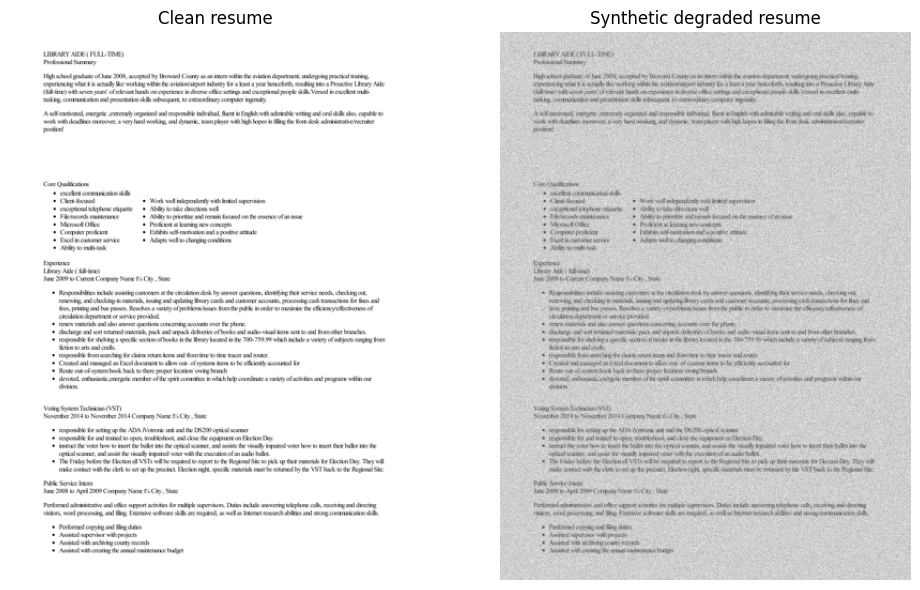

In [9]:

import io
import random
from PIL import ImageFilter, ImageEnhance

def degrade_image(clean_image):
    """Create a synthetic degraded version of a grayscale resume."""

    image = clean_image.copy().convert("L")

    # Random blur
    if random.random() < 0.7:
        image = image.filter(
            ImageFilter.GaussianBlur(
                radius=random.uniform(0.3, 1.5)
            )
        )

    # Random contrast
    image = ImageEnhance.Contrast(image).enhance(
        random.uniform(0.55, 1.0)
    )

    # Random brightness
    image = ImageEnhance.Brightness(image).enhance(
        random.uniform(0.75, 1.1)
    )

    # Convert to an array and add noise
    array = np.asarray(image, dtype=np.float32)
    noise = np.random.normal(
        loc=0.0,
        scale=random.uniform(2.0, 12.0),
        size=array.shape
    )

    array = np.clip(array + noise, 0, 255).astype(np.uint8)
    return Image.fromarray(array, mode="L")


# Preview one clean/degraded pair
sample_clean = Image.open(train_paths[0]).convert("L")
sample_degraded = degrade_image(sample_clean)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))

axes[0].imshow(sample_clean, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Clean resume")
axes[0].axis("off")

axes[1].imshow(sample_degraded, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Synthetic degraded resume")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [10]:

from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

PATCH_SIZE = 128
BATCH_SIZE = 16

class ResumeDataset(Dataset):
    def __init__(self, image_paths, patch_size=128, training=False):
        self.image_paths = image_paths
        self.patch_size = patch_size
        self.training = training

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        # Load clean grayscale resume
        clean = Image.open(self.image_paths[idx]).convert("L")

        # Resize to a consistent size
        clean = clean.resize((384, 512), Image.Resampling.LANCZOS)

        # Random crop for training; centered crop for validation/test
        if self.training:
            left = random.randint(0, 384 - self.patch_size)
            top = random.randint(0, 512 - self.patch_size)
        else:
            left = (384 - self.patch_size) // 2
            top = (512 - self.patch_size) // 2

        clean = clean.crop((
            left,
            top,
            left + self.patch_size,
            top + self.patch_size
        ))

        # Apply random horizontal flip only during training
        # Disabled by default because flipping text is unrealistic.

        degraded = degrade_image(clean)

        # Convert pixel values from [0, 255] to [-1, 1]
        clean_tensor = TF.to_tensor(clean) * 2.0 - 1.0
        degraded_tensor = TF.to_tensor(degraded) * 2.0 - 1.0

        return degraded_tensor, clean_tensor


train_dataset = ResumeDataset(
    train_paths, PATCH_SIZE, training=True
)

val_dataset = ResumeDataset(
    val_paths, PATCH_SIZE, training=False
)

test_dataset = ResumeDataset(
    test_paths, PATCH_SIZE, training=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 125
Validation batches: 16
Test batches: 16


/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")


Degraded batch shape: torch.Size([16, 1, 128, 128])
Clean batch shape: torch.Size([16, 1, 128, 128])
Minimum pixel value: -1.0
Maximum pixel value: 1.0


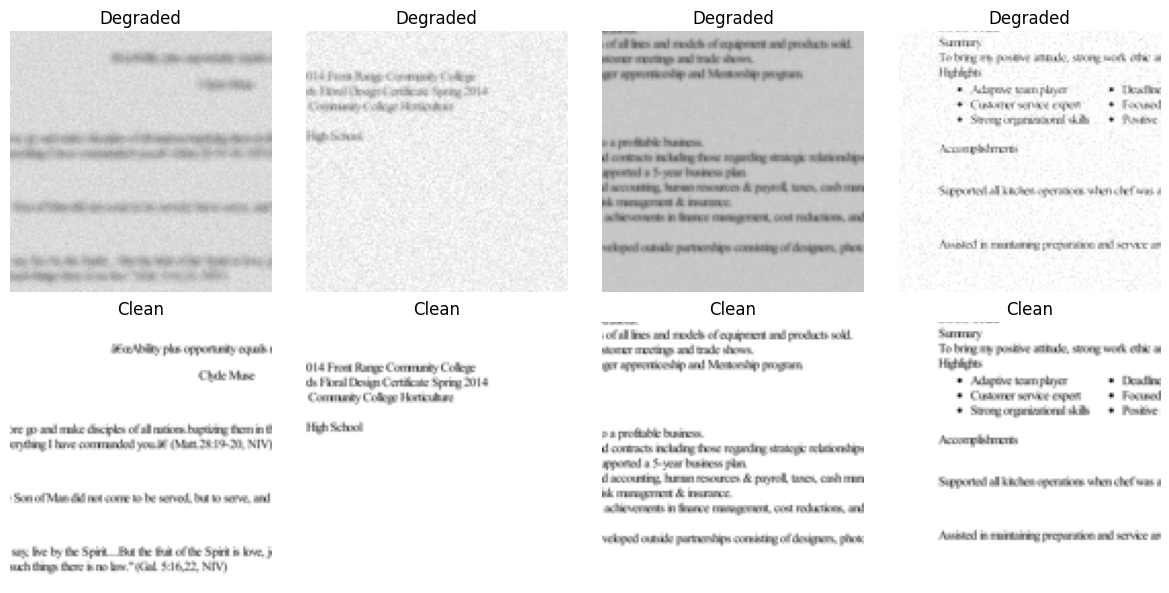

In [11]:

degraded_batch, clean_batch = next(iter(train_loader))

print("Degraded batch shape:", degraded_batch.shape)
print("Clean batch shape:", clean_batch.shape)
print("Minimum pixel value:", clean_batch.min().item())
print("Maximum pixel value:", clean_batch.max().item())

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    axes[0, i].imshow(
        degraded_batch[i, 0].cpu().numpy(),
        cmap="gray", vmin=-1, vmax=1
    )
    axes[0, i].set_title("Degraded")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        clean_batch[i, 0].cpu().numpy(),
        cmap="gray", vmin=-1, vmax=1
    )
    axes[1, i].set_title("Clean")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()


In [12]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import math

# Embedding for the diffusion timestep
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.SiLU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, t):
        half_dim = self.dim // 2

        emb_scale = math.log(10000) / max(half_dim - 1, 1)
        emb = torch.exp(
            torch.arange(half_dim, device=t.device) * -emb_scale
        )

        emb = t.float()[:, None] * emb[None, :]
        emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)

        if self.dim % 2:
            emb = F.pad(emb, (0, 1))

        return self.mlp(emb)


# Residual block with timestep information
class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3, padding=1
        )

        self.time_proj = nn.Linear(time_dim, out_channels)

        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3, padding=1
        )

        self.skip = (
            nn.Conv2d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x, time_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(F.silu(time_emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


# Conditional U-Net
class ConditionalUNet(nn.Module):
    def __init__(self, in_channels=2, base_channels=32):
        super().__init__()

        time_dim = base_channels * 4
        self.time_embedding = TimeEmbedding(time_dim)

        self.input_conv = nn.Conv2d(
            in_channels, base_channels, kernel_size=3, padding=1
        )

        self.down1 = ResBlock(
            base_channels, base_channels, time_dim
        )
        self.downsample1 = nn.Conv2d(
            base_channels, base_channels * 2, 4, stride=2, padding=1
        )

        self.down2 = ResBlock(
            base_channels * 2, base_channels * 2, time_dim
        )
        self.downsample2 = nn.Conv2d(
            base_channels * 2, base_channels * 4, 4, stride=2, padding=1
        )

        self.middle1 = ResBlock(
            base_channels * 4, base_channels * 4, time_dim
        )
        self.middle2 = ResBlock(
            base_channels * 4, base_channels * 4, time_dim
        )

        self.upsample2 = nn.ConvTranspose2d(
            base_channels * 4, base_channels * 2, 4, stride=2, padding=1
        )
        self.up2 = ResBlock(
            base_channels * 4, base_channels * 2, time_dim
        )

        self.upsample1 = nn.ConvTranspose2d(
            base_channels * 2, base_channels, 4, stride=2, padding=1
        )
        self.up1 = ResBlock(
            base_channels * 2, base_channels, time_dim
        )

        self.output_norm = nn.GroupNorm(8, base_channels)
        self.output_conv = nn.Conv2d(
            base_channels, 1, kernel_size=3, padding=1
        )

    def forward(self, x, t, condition):
        # Concatenate diffusion image and degraded resume
        x = torch.cat([x, condition], dim=1)

        time_emb = self.time_embedding(t)

        x0 = self.input_conv(x)

        x1 = self.down1(x0, time_emb)
        x2 = self.downsample1(x1)

        x2 = self.down2(x2, time_emb)
        x3 = self.downsample2(x2)

        x3 = self.middle1(x3, time_emb)
        x3 = self.middle2(x3, time_emb)

        u2 = self.upsample2(x3)
        u2 = torch.cat([u2, x2], dim=1)
        u2 = self.up2(u2, time_emb)

        u1 = self.upsample1(u2)
        u1 = torch.cat([u1, x1], dim=1)
        u1 = self.up1(u1, time_emb)

        return torch.tanh(
            self.output_conv(F.silu(self.output_norm(u1)))
        )


model = ConditionalUNet(base_channels=32).to(DEVICE)

parameter_count = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Model created successfully.")
print("Trainable parameters:", f"{parameter_count:,}")
print("Device:", DEVICE)


Model created successfully.
Trainable parameters: 1,351,873
Device: cuda


In [13]:

model.eval()

with torch.no_grad():
    test_degraded, test_clean = next(iter(train_loader))

    test_degraded = test_degraded.to(DEVICE)
    test_clean = test_clean.to(DEVICE)

    test_t = torch.randint(
        low=0,
        high=1000,
        size=(test_clean.shape[0],),
        device=DEVICE
    )

    # Test with a random diffusion image
    test_noisy = torch.randn_like(test_clean).clamp(-1, 1)

    prediction = model(
        test_noisy,
        test_t,
        test_degraded
    )

print("Input shape:", test_noisy.shape)
print("Condition shape:", test_degraded.shape)
print("Output shape:", prediction.shape)

assert prediction.shape == test_clean.shape, (
    "Model output shape does not match the clean image shape."
)

print("Model shape test passed.")


/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")


Input shape: torch.Size([16, 1, 128, 128])
Condition shape: torch.Size([16, 1, 128, 128])
Output shape: torch.Size([16, 1, 128, 128])
Model shape test passed.


In [14]:

import torch
import math

# Number of diffusion timesteps
T = 1000

def cosine_beta_schedule(timesteps, s=0.008):
    """
    Cosine schedule for the forward diffusion process.
    """
    steps = timesteps + 1

    x = torch.linspace(0, timesteps, steps, dtype=torch.float64)

    alphas_cumprod = torch.cos(
        ((x / timesteps) + s) / (1 + s) * math.pi * 0.5
    ) ** 2

    alphas_cumprod = alphas_cumprod / alphas_cumprod[0]

    betas = 1 - (
        alphas_cumprod[1:] / alphas_cumprod[:-1]
    )

    return torch.clip(betas, 0.0001, 0.999).float()


betas = cosine_beta_schedule(T).to(DEVICE)

alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)

sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

print("Timesteps:", T)
print("Beta shape:", betas.shape)
print("Alpha cumulative product shape:", alphas_cumprod.shape)
print("First beta:", betas[0].item())
print("Last beta:", betas[-1].item())
print("Schedule created successfully.")


Timesteps: 1000
Beta shape: torch.Size([1000])
Alpha cumulative product shape: torch.Size([1000])
First beta: 9.999999747378752e-05
Last beta: 0.9990000128746033
Schedule created successfully.


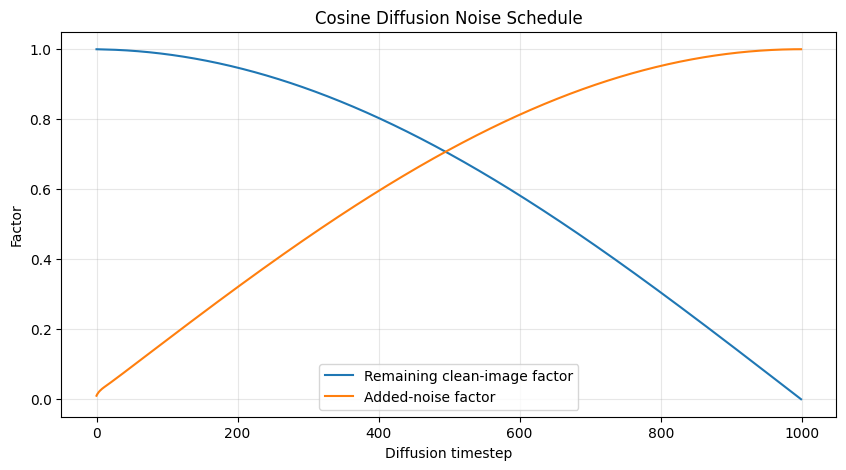

In [15]:

plt.figure(figsize=(10, 5))

plt.plot(
    sqrt_alphas_cumprod.detach().cpu().numpy(),
    label="Remaining clean-image factor"
)

plt.plot(
    sqrt_one_minus_alphas_cumprod.detach().cpu().numpy(),
    label="Added-noise factor"
)

plt.xlabel("Diffusion timestep")
plt.ylabel("Factor")
plt.title("Cosine Diffusion Noise Schedule")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [16]:

def q_sample(x_start, t, noise=None):
    """Add diffusion noise to a clean image at timestep t."""

    if noise is None:
        noise = torch.randn_like(x_start)

    sqrt_alpha = sqrt_alphas_cumprod[t].view(-1, 1, 1, 1)
    sqrt_noise = sqrt_one_minus_alphas_cumprod[t].view(-1, 1, 1, 1)

    x_t = sqrt_alpha * x_start + sqrt_noise * noise
    return x_t, noise


# Test the forward diffusion process
clean = clean_batch.to(DEVICE)
random_t = torch.randint(0, T, (clean.shape[0],), device=DEVICE)

noisy, _ = q_sample(clean, random_t)

print("Clean image shape:", clean.shape)
print("Noisy image shape:", noisy.shape)
print("Forward diffusion test passed.")


Clean image shape: torch.Size([16, 1, 128, 128])
Noisy image shape: torch.Size([16, 1, 128, 128])
Forward diffusion test passed.


In [17]:

import os
import time
import pandas as pd

EPOCHS = 70
LEARNING_RATE = 2e-4

OUTPUT_DIR = "/content/resume_diffusion_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_CHECKPOINT = os.path.join(OUTPUT_DIR, "best_model.pt")
LATEST_CHECKPOINT = os.path.join(OUTPUT_DIR, "latest_model.pt")
HISTORY_CSV = os.path.join(OUTPUT_DIR, "training_history.csv")

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

USE_AMP = DEVICE.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

history = {
    "epoch": [],
    "train_mse": [],
    "val_mse": [],
    "learning_rate": []
}

best_val_mse = float("inf")

print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Mixed precision:", USE_AMP)
print("Checkpoint folder:", OUTPUT_DIR)


Epochs: 70
Learning rate: 0.0002
Mixed precision: True
Checkpoint folder: /content/resume_diffusion_output


In [18]:

for epoch in range(EPOCHS):
    epoch_start = time.time()

    # ---------------- TRAINING ----------------
    model.train()
    train_loss_sum = 0.0
    train_count = 0

    for degraded, clean in train_loader:
        degraded = degraded.to(DEVICE)
        clean = clean.to(DEVICE)

        t = torch.randint(
            0, T, (clean.shape[0],), device=DEVICE
        )

        x_t, _ = q_sample(clean, t)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            # Predict clean image x0 from noisy image and condition
            predicted_clean = model(x_t, t, degraded)
            loss = F.mse_loss(predicted_clean, clean)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()

        batch_size = clean.shape[0]
        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

    train_mse = train_loss_sum / max(train_count, 1)

    # ---------------- VALIDATION ----------------
    model.eval()
    val_loss_sum = 0.0
    val_count = 0

    with torch.no_grad():
        for degraded, clean in val_loader:
            degraded = degraded.to(DEVICE)
            clean = clean.to(DEVICE)

            t = torch.randint(
                0, T, (clean.shape[0],), device=DEVICE
            )

            x_t, _ = q_sample(clean, t)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=USE_AMP
            ):
                predicted_clean = model(x_t, t, degraded)
                val_loss = F.mse_loss(predicted_clean, clean)

            batch_size = clean.shape[0]
            val_loss_sum += val_loss.item() * batch_size
            val_count += batch_size

    val_mse = val_loss_sum / max(val_count, 1)

    scheduler.step()

    history["epoch"].append(epoch + 1)
    history["train_mse"].append(train_mse)
    history["val_mse"].append(val_mse)
    history["learning_rate"].append(
        optimizer.param_groups[0]["lr"]
    )

    # Save the best model based on validation MSE
    if val_mse < best_val_mse:
        best_val_mse = val_mse
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_mse": val_mse
        }, BEST_CHECKPOINT)

    # Save latest checkpoint and training history each epoch
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_mse": val_mse
    }, LATEST_CHECKPOINT)

    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    elapsed = time.time() - epoch_start

    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] | "
        f"Train MSE: {train_mse:.6f} | "
        f"Val MSE: {val_mse:.6f} | "
        f"Time: {elapsed:.1f}s"
    )

print("\nTraining finished.")
print("Best validation MSE:", best_val_mse)
print("Best checkpoint:", BEST_CHECKPOINT)
print("Training history:", HISTORY_CSV)


/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")


Epoch [01/70] | Train MSE: 0.043021 | Val MSE: 0.016247 | Time: 11.6s


/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")


Epoch [02/70] | Train MSE: 0.012179 | Val MSE: 0.011511 | Time: 9.6s


/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")


Epoch [03/70] | Train MSE: 0.010421 | Val MSE: 0.010353 | Time: 10.3s


... (130 outputs left out)

/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")


Epoch [69/70] | Train MSE: 0.005505 | Val MSE: 0.006970 | Time: 10.3s


/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")


Epoch [70/70] | Train MSE: 0.005625 | Val MSE: 0.005772 | Time: 10.5s

Training finished.
Best validation MSE: 0.005592388746839377
Best checkpoint: /content/resume_diffusion_output/best_model.pt
Training history: /content/resume_diffusion_output/training_history.csv


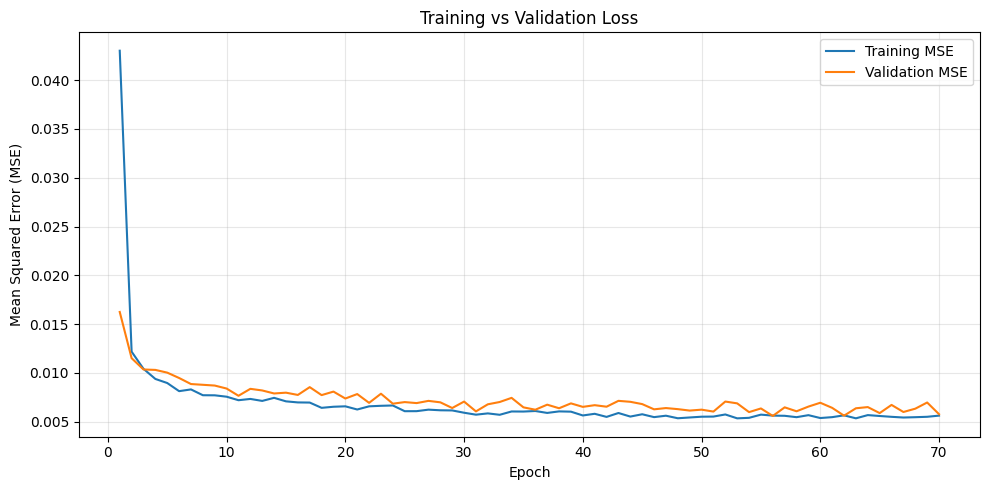

Epochs recorded: 70
Final training MSE: 0.0056247610513732
Final validation MSE: 0.0057719671317646
Best validation MSE: 0.0055923887468393


In [19]:

import pandas as pd
import matplotlib.pyplot as plt
import os

history_df = pd.read_csv(HISTORY_CSV)

plt.figure(figsize=(10, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_mse"],
    label="Training MSE"
)
plt.plot(
    history_df["epoch"],
    history_df["val_mse"],
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "training_validation_loss.png"),
    dpi=200
)
plt.show()

print("Epochs recorded:", len(history_df))
print("Final training MSE:", history_df["train_mse"].iloc[-1])
print("Final validation MSE:", history_df["val_mse"].iloc[-1])
print("Best validation MSE:", history_df["val_mse"].min())


In [20]:

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint epoch:", checkpoint["epoch"])
print("Best checkpoint validation MSE:", checkpoint["val_mse"])
print("Best model loaded successfully.")


Best checkpoint epoch: 56
Best checkpoint validation MSE: 0.005592388746839377
Best model loaded successfully.


/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")


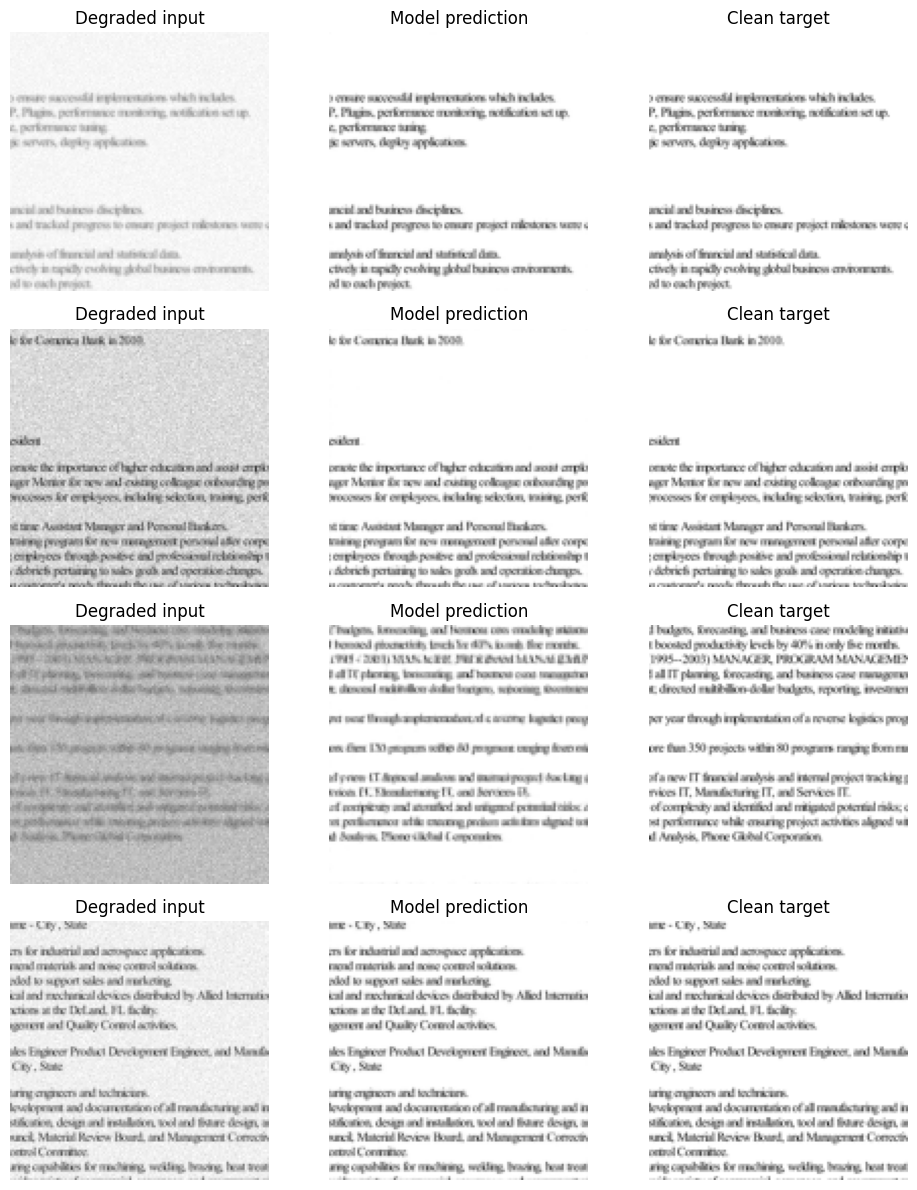

In [21]:

model.eval()

degraded, clean = next(iter(test_loader))
degraded = degraded.to(DEVICE)
clean = clean.to(DEVICE)

# Use a moderate timestep for this diagnostic preview
t = torch.full(
    (clean.shape[0],),
    500,
    device=DEVICE,
    dtype=torch.long
)

with torch.no_grad():
    x_t, _ = q_sample(clean, t)
    predicted = model(x_t, t, degraded)

# Convert [-1, 1] tensors into displayable [0, 1] images
def display_tensor(tensor):
    return ((tensor.detach().cpu().clamp(-1, 1) + 1) / 2).squeeze().numpy()

n = min(4, clean.shape[0])
fig, axes = plt.subplots(n, 3, figsize=(10, 3 * n))

if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n):
    axes[i, 0].imshow(display_tensor(degraded[i]), cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title("Degraded input")

    axes[i, 1].imshow(display_tensor(predicted[i]), cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Model prediction")

    axes[i, 2].imshow(display_tensor(clean[i]), cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("Clean target")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [22]:

%pip install -q scikit-image


In [23]:

import numpy as np
import pandas as pd
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

model.eval()

results = []
all_predictions = []
all_targets = []

with torch.no_grad():
    for degraded, clean in test_loader:
        degraded = degraded.to(DEVICE)
        clean = clean.to(DEVICE)

        # Same diagnostic timestep for every test image
        t = torch.full(
            (clean.shape[0],),
            500,
            device=DEVICE,
            dtype=torch.long
        )

        noisy, _ = q_sample(clean, t)
        predicted = model(noisy, t, degraded)

        # Convert images from [-1, 1] to [0, 1]
        predicted = ((predicted.clamp(-1, 1) + 1) / 2)
        clean_display = ((clean.clamp(-1, 1) + 1) / 2)

        predicted_np = predicted.cpu().numpy()
        clean_np = clean_display.cpu().numpy()

        for i in range(predicted.shape[0]):
            pred_img = predicted_np[i, 0]
            target_img = clean_np[i, 0]

            mse_value = float(np.mean((pred_img - target_img) ** 2))
            psnr_value = float(
                psnr(target_img, pred_img, data_range=1.0)
            )
            ssim_value = float(
                ssim(target_img, pred_img, data_range=1.0)
            )

            results.append({
                "MSE": mse_value,
                "PSNR_dB": psnr_value,
                "SSIM": ssim_value
            })

            all_predictions.append(pred_img)
            all_targets.append(target_img)

metrics_df = pd.DataFrame(results)

metrics_path = os.path.join(
    OUTPUT_DIR, "test_image_metrics.csv"
)
metrics_df.to_csv(metrics_path, index=False)

print("Test images evaluated:", len(metrics_df))
print("\nAverage test metrics:")
print(metrics_df.mean(numeric_only=True).round(4))
print("\nSaved metrics to:", metrics_path)


/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")
/tmp/ipykernel_434/1876557494.py:37: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(array, mode="L")


Test images evaluated: 249

Average test metrics:
MSE         0.0017
PSNR_dB    30.2064
SSIM        0.9672
dtype: float64

Saved metrics to: /content/resume_diffusion_output/test_image_metrics.csv


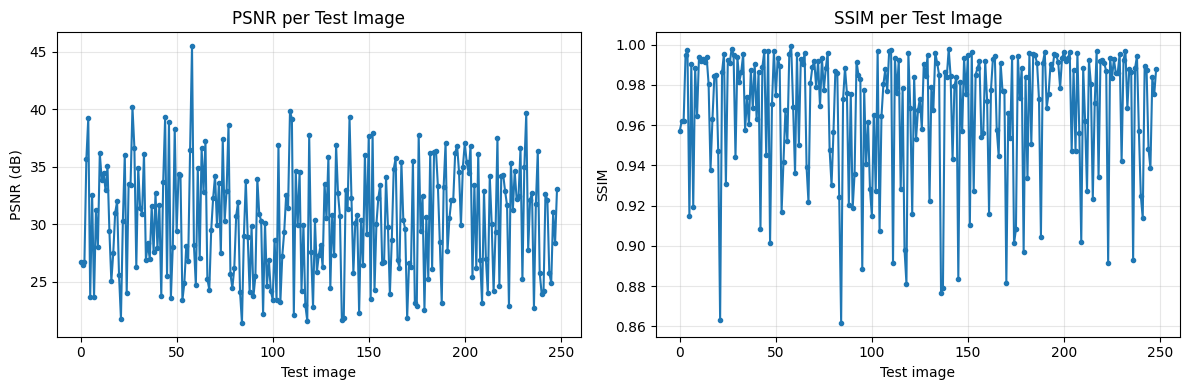

In [24]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(metrics_df["PSNR_dB"], marker="o", markersize=3)
axes[0].set_title("PSNR per Test Image")
axes[0].set_xlabel("Test image")
axes[0].set_ylabel("PSNR (dB)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(metrics_df["SSIM"], marker="o", markersize=3)
axes[1].set_title("SSIM per Test Image")
axes[1].set_xlabel("Test image")
axes[1].set_ylabel("SSIM")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "test_quality_metrics.png"),
    dpi=200
)
plt.show()


In [25]:

%pip install -q torchmetrics torch-fidelity


In [26]:

from torchmetrics.image.fid import FrechetInceptionDistance

fid_metric = FrechetInceptionDistance(
    feature=2048,
    normalize=False
).to(DEVICE)

# FID expects 3-channel uint8 images in [0, 255].
# Repeat grayscale channels to form RGB-like inputs.
max_fid_images = min(128, len(all_predictions))

for i in range(max_fid_images):
    pred = torch.tensor(
        all_predictions[i], device=DEVICE
    )[None, None, :, :]

    target = torch.tensor(
        all_targets[i], device=DEVICE
    )[None, None, :, :]

    pred = (pred * 255).round().clamp(0, 255).to(torch.uint8)
    target = (target * 255).round().clamp(0, 255).to(torch.uint8)

    pred_rgb = pred.repeat(1, 3, 1, 1)
    target_rgb = target.repeat(1, 3, 1, 1)

    fid_metric.update(target_rgb, real=True)
    fid_metric.update(pred_rgb, real=False)

fid_value = fid_metric.compute().item()

print("Number of images used for FID:", max_fid_images)
print("FID:", fid_value)


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 111MB/s]


Number of images used for FID: 128
FID: 6.065732955932617


In [27]:

import os
import torch
import json

FINAL_MODEL_PATH = os.path.join(
    OUTPUT_DIR, "resume_diffusion_final.pt"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "timesteps": T,
    "image_size": PATCH_SIZE,
    "base_channels": 32,
    "best_validation_mse": float(best_val_mse)
}, FINAL_MODEL_PATH)

print("Final model saved to:", FINAL_MODEL_PATH)
print("Model size (MB):", round(
    os.path.getsize(FINAL_MODEL_PATH) / (1024 * 1024), 2
))


Final model saved to: /content/resume_diffusion_output/resume_diffusion_final.pt
Model size (MB): 5.18


In [28]:

summary = {
    "epochs_completed": int(len(history_df)),
    "best_validation_mse": float(best_val_mse),
    "final_training_mse": float(history_df["train_mse"].iloc[-1]),
    "final_validation_mse": float(history_df["val_mse"].iloc[-1]),
    "mean_test_mse": float(metrics_df["MSE"].mean()),
    "mean_test_psnr_db": float(metrics_df["PSNR_dB"].mean()),
    "mean_test_ssim": float(metrics_df["SSIM"].mean())
}

# Include FID only if it was calculated successfully
if "fid_value" in globals():
    summary["fid"] = float(fid_value)

summary_path = os.path.join(OUTPUT_DIR, "results_summary.json")

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print(json.dumps(summary, indent=4))
print("\nSaved summary to:", summary_path)


{
    "epochs_completed": 70,
    "best_validation_mse": 0.005592388746839377,
    "final_training_mse": 0.0056247610513732,
    "final_validation_mse": 0.0057719671317646,
    "mean_test_mse": 0.0016715711113048533,
    "mean_test_psnr_db": 30.206449948042604,
    "mean_test_ssim": 0.9671961924522894,
    "fid": 6.065732955932617
}

Saved summary to: /content/resume_diffusion_output/results_summary.json
